In [62]:
import json 
import os
import numpy as np
from PIL import Image
from matplotlib import pyplot as plt
import torch
import torch.nn as nn
from torchvision import models, transforms
import torch.nn.functional as F
import random


In [63]:
!pip install scikit-image

In [64]:
from skimage.segmentation import mark_boundaries


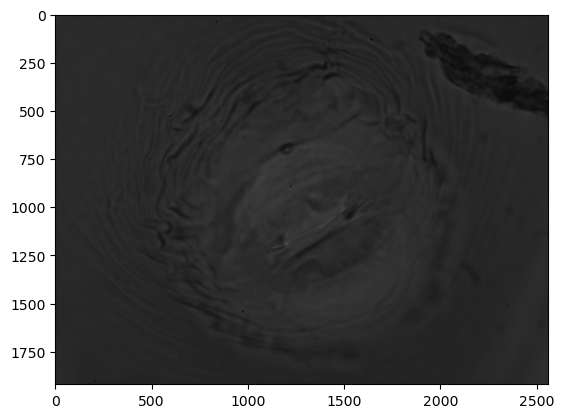

In [65]:
def get_image(path):
    with open(os.path.abspath(path), 'rb') as f:
        with Image.open(f) as img:
            return img.convert('RGB') 
        
img = get_image('/home/dbtproject/barsha/Image/test_set/Class0_Graminicola/Chaibasa_86_PP_6.tiff')
plt.imshow(img)

In [66]:
# resize and take the center part of image to what our model expects
def get_input_transform():
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                    std=[0.229, 0.224, 0.225])       
    transf = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        normalize
    ])    

    return transf

def get_input_tensors(img):
    transf = get_input_transform()
    # unsqeeze converts single image to batch of 1
    return transf(img).unsqueeze(0)

In [67]:

np,random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


In [68]:
#ResNet-50 Model

model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.eval().to(device)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [69]:
# read imagenet classes
weights=models.ResNet50_Weights.DEFAULT
idx2label = weights.meta["categories"]
print(idx2label[60])  # example


night snake


In [70]:
img_t = get_input_tensors(img)
img_t = img_t.to(device)
logits = model(img_t)
probs = F.softmax(logits, dim=1).cpu()
probs5 = probs.topk(5)
tuple((p,c, idx2label[c]) for p, c in zip(probs5[0][0].detach().numpy(), probs5[1][0].detach().numpy()))

((0.39855656, 111, 'nematode'),
 (0.106788106, 659, 'mixing bowl'),
 (0.02348615, 896, 'washbasin'),
 (0.023027131, 936, 'head cabbage'),
 (0.015323006, 944, 'artichoke'))

In [71]:
def get_pil_transform():
    transf = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.CenterCrop(224),
    ])    

    return transf

def get_preprocess_transform():
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                    std=[0.229, 0.224, 0.225])       
    
    tf = transforms.Compose([
        transforms.ToTensor(),
        normalize    
    ])

    return tf 

pil_tf = get_pil_transform()
preprocess_tf = get_preprocess_transform()

In [72]:
def batch_predict(images):
    model.to(device)
    model.eval()
    batch = torch.stack(tuple(preprocess_tf(i) for i in images), dim = 0)
    batch = batch.to(device)

    logits = model(batch)
    probs = F.softmax(logits, dim = 1)
    return probs.detach().cpu().numpy()


In [73]:
test_pred = batch_predict([pil_tf(img)])
test_pred.squeeze().argmax()


111

In [74]:
#use lime to explain the model
!pip install lime


In [75]:
from lime import lime_image
explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(np.array(pil_tf(img)),
                                         batch_predict, #classfication function
                                         top_labels = 5,
                                         hide_color = 0,
                                         num_samples = 1000)

100%|██████████| 1000/1000 [00:02<00:00, 404.73it/s]


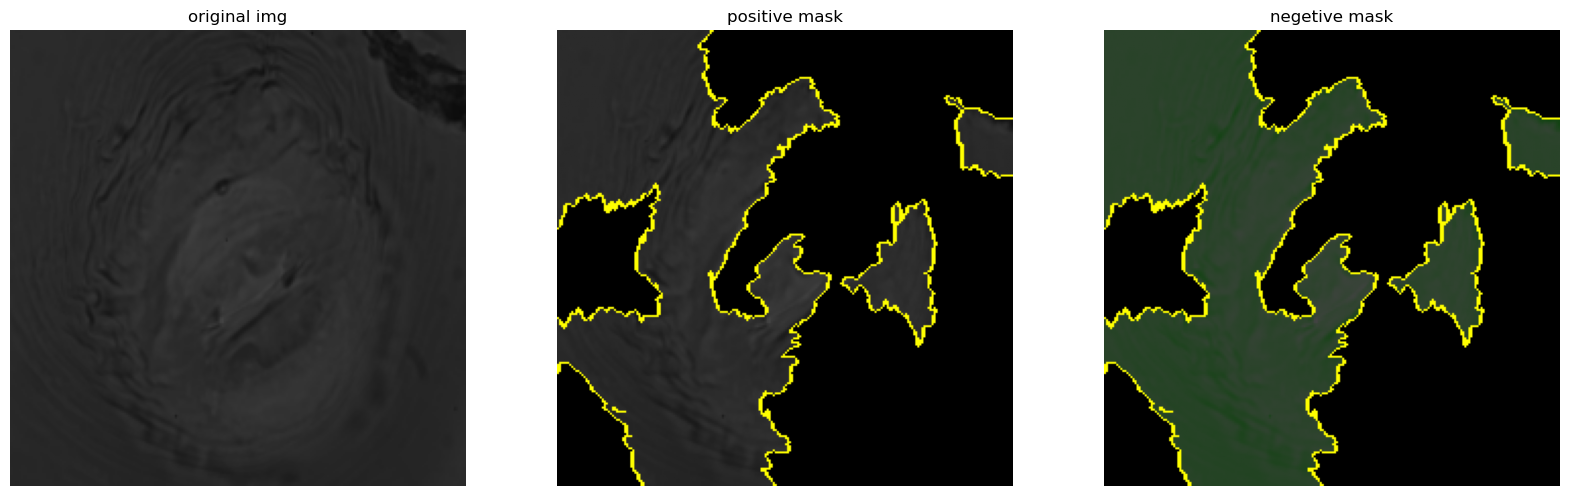

In [76]:
fig, axes = plt.subplots(1,3, figsize = (20,10))

axes[0].imshow(pil_tf(img))
axes[0].axis('off')
axes[0].set_title('original img')

temp, mask = explanation.get_image_and_mask(explanation.top_labels[0],
                                            positive_only = True,
                                            # negative_only = False,
                                            num_features = 10,
                                            hide_rest = True)

img_boundary = mark_boundaries(temp/255.0, mask)
axes[1].imshow(img_boundary)
axes[1].set_title('positive mask')
axes[1].axis('off')

temp, mask = explanation.get_image_and_mask(explanation.top_labels[0],
                                            positive_only = False,
                                            # negative_only = True,
                                            num_features = 10,
                                            hide_rest = True)

img_boundary = mark_boundaries(temp/255.0, mask)
axes[2].imshow(img_boundary)
axes[2].set_title('negetive mask')
axes[2].axis('off')

plt.show()